# 300W-LP (300W Large Pose) Dataset - EDA

本notebook用于探索和分析300W-LP大姿态人脸数据集。

## 数据集信息
- **来源**: "Face Alignment Across Large Poses: A 3D Solution" (CVPR 2016)
- **类型**: 合成大姿态人脸数据集
- **图像数**: 约 61,225 张图像
- **原始数据源**: 基于 300W 数据集通过 3D 人脸模型变换生成
- **姿态范围**: Yaw 角度扩展至 [-90°, +90°]

## 子数据集
- **AFW**: Annotated Faces in the Wild
- **HELEN**: 高分辨率人脸图像
- **IBUG**: 极具挑战性的人脸图像
- **LFPW**: Labeled Face Parts in the Wild
- **Flip版本**: 上述数据集的水平翻转版本 (数据增强)

## 标注格式
每张图像对应一个 `.mat` 文件，包含:
- **Pose_Para**: 姿态参数 (pitch, yaw, roll, Tx, Ty, Tz, s)
- **Shape_Para**: 形状参数 (BFM模型系数)
- **Exp_Para**: 表情参数
- **Color_Para**: 颜色参数
- **Illum_Para**: 光照参数
- **roi**: 人脸区域边界框

landmarks文件夹中的 `*_pts.mat` 文件包含:
- **pts_2d**: 68个2D人脸关键点坐标
- **pts_3d**: 68个3D人脸关键点坐标

## 文件结构
```
300W_LP/
├── Code/                    # 官方读取代码 (MATLAB)
├── landmarks/               # 关键点标注
│   ├── AFW/                 # *_pts.mat 文件
│   ├── HELEN/
│   ├── IBUG/
│   └── LFPW/
├── AFW/                     # 图像和参数 (.jpg + .mat)
├── AFW_Flip/                # 翻转版本
├── HELEN/
├── HELEN_Flip/
├── IBUG/
├── IBUG_Flip/
├── LFPW/
└── LFPW_Flip/
```


In [1]:
import os
import glob
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict
import cv2
from scipy.io import loadmat
from tqdm import tqdm

# 中文显示设置
mpl.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti SC', 'Songti SC', 'Arial Unicode MS']
mpl.rcParams['axes.unicode_minus'] = False

# 设置数据集路径 - 请根据实际情况修改
DATASET_ROOT = os.path.expanduser("~/temp/public_dataset/300W_LP")

# 定义子数据集 (不含翻转版本)
SUBSETS = ['AFW', 'HELEN', 'IBUG', 'LFPW']
SUBSETS_WITH_FLIP = SUBSETS + [f"{s}_Flip" for s in SUBSETS]

# 检查目录结构
print("=" * 60)
print("300W-LP Dataset Directory Structure")
print("=" * 60)

for item in sorted(os.listdir(DATASET_ROOT)):
    item_path = os.path.join(DATASET_ROOT, item)
    if os.path.isdir(item_path):
        file_count = len([f for f in os.listdir(item_path) if os.path.isfile(os.path.join(item_path, f))])
        print(f"📁 {item}/ ({file_count} files)")
    else:
        print(f"📄 {item}")


300W-LP Dataset Directory Structure
📁 AFW/ (10414 files)
📁 AFW_Flip/ (10414 files)
📁 Code/ (10 files)
📁 HELEN/ (75352 files)
📁 HELEN_Flip/ (75352 files)
📁 IBUG/ (3572 files)
📁 IBUG_Flip/ (3572 files)
📁 LFPW/ (33112 files)
📁 LFPW_Flip/ (33112 files)
📁 landmarks/ (0 files)


## 1. 数据集统计概览


In [2]:
# 统计每个子数据集的图像和标注数量
print("=" * 60)
print("数据集统计信息")
print("=" * 60)

stats = {}
total_images = 0
total_mat_files = 0

for subset in SUBSETS_WITH_FLIP:
    subset_path = os.path.join(DATASET_ROOT, subset)
    if os.path.exists(subset_path):
        jpg_files = glob.glob(os.path.join(subset_path, "*.jpg"))
        mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
        stats[subset] = {
            'images': len(jpg_files),
            'mat_files': len(mat_files)
        }
        total_images += len(jpg_files)
        total_mat_files += len(mat_files)

# 统计 landmarks 文件夹
landmarks_stats = {}
for subset in SUBSETS:
    landmark_path = os.path.join(DATASET_ROOT, "landmarks", subset)
    if os.path.exists(landmark_path):
        pts_files = glob.glob(os.path.join(landmark_path, "*_pts.mat"))
        landmarks_stats[subset] = len(pts_files)

# 显示统计结果
print(f"\n{'子数据集':<15} {'图像数':>10} {'参数文件':>10}")
print("-" * 40)
for subset, info in stats.items():
    print(f"{subset:<15} {info['images']:>10,} {info['mat_files']:>10,}")

print("-" * 40)
print(f"{'总计':<15} {total_images:>10,} {total_mat_files:>10,}")

print(f"\n\n{'landmarks子集':<15} {'关键点文件':>12}")
print("-" * 30)
for subset, count in landmarks_stats.items():
    print(f"{subset:<15} {count:>12,}")
print("-" * 30)
print(f"{'总计':<15} {sum(landmarks_stats.values()):>12,}")


数据集统计信息

子数据集                   图像数       参数文件
----------------------------------------
AFW                  5,207      5,207
HELEN               37,676     37,676
IBUG                 1,786      1,786
LFPW                16,556     16,556
AFW_Flip             5,207      5,207
HELEN_Flip          37,676     37,676
IBUG_Flip            1,786      1,786
LFPW_Flip           16,556     16,556
----------------------------------------
总计                 122,450    122,450


landmarks子集            关键点文件
------------------------------
AFW                    5,207
HELEN                 37,676
IBUG                   1,786
LFPW                  16,556
------------------------------
总计                    61,225


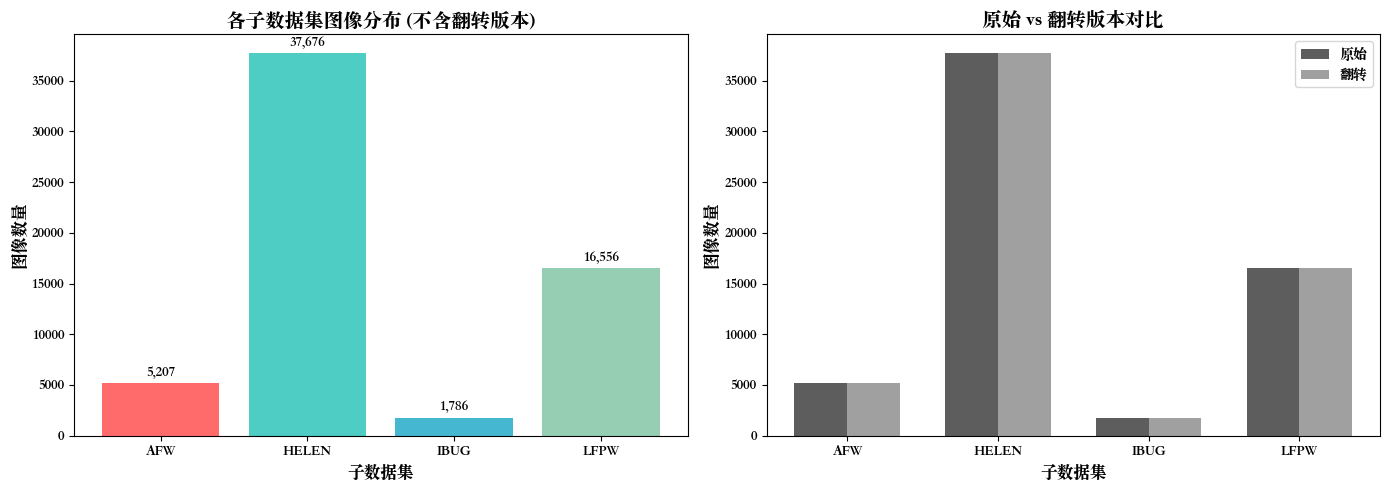

✅ 图表已保存: 300w_lp_subset_distribution.png


In [3]:
# 可视化数据分布
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 子数据集图像分布 (不含翻转版本)
original_subsets = {k: v for k, v in stats.items() if '_Flip' not in k}
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

ax1 = axes[0]
bars1 = ax1.bar(original_subsets.keys(), [v['images'] for v in original_subsets.values()], color=colors)
ax1.set_xlabel('子数据集', fontsize=12)
ax1.set_ylabel('图像数量', fontsize=12)
ax1.set_title('各子数据集图像分布 (不含翻转版本)', fontsize=14, fontweight='bold')
ax1.bar_label(bars1, fmt='{:,.0f}', padding=3)

# 原始 vs 翻转版本对比
ax2 = axes[1]
x = np.arange(len(SUBSETS))
width = 0.35

original_counts = [stats[s]['images'] for s in SUBSETS]
flip_counts = [stats[f"{s}_Flip"]['images'] for s in SUBSETS]

bars_orig = ax2.bar(x - width/2, original_counts, width, label='原始', color='#5D5D5D')
bars_flip = ax2.bar(x + width/2, flip_counts, width, label='翻转', color='#A0A0A0')

ax2.set_xlabel('子数据集', fontsize=12)
ax2.set_ylabel('图像数量', fontsize=12)
ax2.set_title('原始 vs 翻转版本对比', fontsize=14, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(SUBSETS)
ax2.legend()

plt.tight_layout()
plt.savefig('300w_lp_subset_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_subset_distribution.png")


## 2. MAT 文件结构解析

探索单个样本的 `.mat` 文件结构，了解数据格式


In [4]:
# 加载一个样本 .mat 文件，查看内部结构
sample_subset = "AFW"
sample_mat_files = glob.glob(os.path.join(DATASET_ROOT, sample_subset, "*.mat"))[:1]

if sample_mat_files:
    sample_mat = loadmat(sample_mat_files[0])
    sample_name = os.path.basename(sample_mat_files[0])
    
    print("=" * 60)
    print(f"样本文件: {sample_name}")
    print("=" * 60)
    print("\n📦 MAT 文件包含的字段:")
    print("-" * 40)
    
    for key, value in sample_mat.items():
        if not key.startswith('__'):
            if isinstance(value, np.ndarray):
                print(f"  {key:<20} shape: {value.shape}, dtype: {value.dtype}")
            else:
                print(f"  {key:<20} type: {type(value).__name__}")
    
    print("\n📋 各字段详细信息:")
    print("-" * 40)
    
    # 姿态参数详解
    if 'Pose_Para' in sample_mat:
        pose = sample_mat['Pose_Para'].flatten()
        print(f"\n🎯 Pose_Para (姿态参数):")
        print(f"   pitch (绕X轴): {np.degrees(pose[0]):.2f}°")
        print(f"   yaw   (绕Y轴): {np.degrees(pose[1]):.2f}°")
        print(f"   roll  (绕Z轴): {np.degrees(pose[2]):.2f}°")
        if len(pose) > 3:
            print(f"   Tx: {pose[3]:.4f}, Ty: {pose[4]:.4f}, Tz: {pose[5]:.4f}")
        if len(pose) > 6:
            print(f"   scale: {pose[6]:.4f}")
    
    # 其他参数简要展示
    for key in ['Shape_Para', 'Exp_Para', 'Color_Para', 'Illum_Para']:
        if key in sample_mat:
            arr = sample_mat[key]
            print(f"\n📊 {key}: shape={arr.shape}, min={arr.min():.4f}, max={arr.max():.4f}")
    
    if 'roi' in sample_mat:
        roi = sample_mat['roi'].flatten()
        print(f"\n🖼️ roi (边界框): [{roi[0]:.0f}, {roi[1]:.0f}, {roi[2]:.0f}, {roi[3]:.0f}]")


样本文件: AFW_2201628776_1_5.mat

📦 MAT 文件包含的字段:
----------------------------------------
  pt2d                 shape: (2, 68), dtype: float64
  roi                  shape: (1, 4), dtype: int16
  Illum_Para           shape: (1, 10), dtype: float64
  Color_Para           shape: (1, 7), dtype: float32
  Tex_Para             shape: (199, 1), dtype: float64
  Shape_Para           shape: (199, 1), dtype: float64
  Exp_Para             shape: (29, 1), dtype: float64
  Pose_Para            shape: (1, 7), dtype: float32

📋 各字段详细信息:
----------------------------------------

🎯 Pose_Para (姿态参数):
   pitch (绕X轴): -1.90°
   yaw   (绕Y轴): 52.63°
   roll  (绕Z轴): 7.45°
   Tx: 270.2205, Ty: 176.2128, Tz: -70.6193
   scale: 0.0012

📊 Shape_Para: shape=(199, 1), min=-359747.7500, max=258271.2969

📊 Exp_Para: shape=(29, 1), min=-1.0555, max=0.3061

📊 Color_Para: shape=(1, 7), min=0.1919, max=1.0000

📊 Illum_Para: shape=(1, 10), min=0.0000, max=20.0000

🖼️ roi (边界框): [427, 185, 920, 678]


In [5]:
# 加载对应的 landmarks 文件
landmark_sample_name = sample_name.replace('.mat', '_pts.mat')
landmark_path = os.path.join(DATASET_ROOT, "landmarks", sample_subset, landmark_sample_name)

if os.path.exists(landmark_path):
    landmark_mat = loadmat(landmark_path)
    
    print("=" * 60)
    print(f"关键点文件: {landmark_sample_name}")
    print("=" * 60)
    print("\n📦 Landmark MAT 文件包含的字段:")
    print("-" * 40)
    
    for key, value in landmark_mat.items():
        if not key.startswith('__'):
            if isinstance(value, np.ndarray):
                print(f"  {key:<20} shape: {value.shape}, dtype: {value.dtype}")
    
    # 显示2D和3D关键点详情
    if 'pts_2d' in landmark_mat:
        pts_2d = landmark_mat['pts_2d']
        print(f"\n🎯 pts_2d (2D关键点): {pts_2d.shape[0]} 个点")
        print(f"   X 范围: [{pts_2d[:, 0].min():.2f}, {pts_2d[:, 0].max():.2f}]")
        print(f"   Y 范围: [{pts_2d[:, 1].min():.2f}, {pts_2d[:, 1].max():.2f}]")
    
    if 'pts_3d' in landmark_mat:
        pts_3d = landmark_mat['pts_3d']
        print(f"\n🎯 pts_3d (3D关键点): {pts_3d.shape[0]} 个点")
        print(f"   X 范围: [{pts_3d[:, 0].min():.2f}, {pts_3d[:, 0].max():.2f}]")
        print(f"   Y 范围: [{pts_3d[:, 1].min():.2f}, {pts_3d[:, 1].max():.2f}]")
        if pts_3d.shape[1] > 2:
            print(f"   Z 范围: [{pts_3d[:, 2].min():.2f}, {pts_3d[:, 2].max():.2f}]")
else:
    print(f"⚠️ 未找到对应的关键点文件: {landmark_path}")


关键点文件: AFW_2201628776_1_5_pts.mat

📦 Landmark MAT 文件包含的字段:
----------------------------------------
  pts_3d               shape: (68, 2), dtype: float32
  pts_2d               shape: (68, 2), dtype: float32

🎯 pts_2d (2D关键点): 68 个点
   X 范围: [148.12, 304.68]
   Y 范围: [211.36, 386.87]

🎯 pts_3d (3D关键点): 68 个点
   X 范围: [148.12, 304.68]
   Y 范围: [211.36, 386.87]


## 3. 样本可视化

展示图像及其对应的68个人脸关键点


In [6]:
def load_sample(subset, sample_name):
    """加载单个样本的图像、参数和关键点"""
    base_name = sample_name.replace('.jpg', '').replace('.mat', '')
    
    # 图像路径
    img_path = os.path.join(DATASET_ROOT, subset, f"{base_name}.jpg")
    # 参数路径
    mat_path = os.path.join(DATASET_ROOT, subset, f"{base_name}.mat")
    # 关键点路径 (仅对非Flip版本存在)
    subset_base = subset.replace('_Flip', '')
    landmark_path = os.path.join(DATASET_ROOT, "landmarks", subset_base, f"{base_name}_pts.mat")
    
    result = {'name': base_name}
    
    # 加载图像
    if os.path.exists(img_path):
        result['image'] = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    
    # 加载参数
    if os.path.exists(mat_path):
        mat = loadmat(mat_path)
        result['pose'] = mat.get('Pose_Para', np.array([])).flatten()
        result['roi'] = mat.get('roi', np.array([])).flatten()
    
    # 加载关键点
    if os.path.exists(landmark_path):
        landmark_mat = loadmat(landmark_path)
        result['pts_2d'] = landmark_mat.get('pts_2d', np.array([]))
        result['pts_3d'] = landmark_mat.get('pts_3d', np.array([]))
    
    return result

def plot_landmarks_on_image(ax, image, pts, pts_type='2d', color='lime', markersize=3):
    """在图像上绘制关键点"""
    ax.imshow(image)
    
    if len(pts) > 0:
        # 绘制关键点
        ax.scatter(pts[:, 0], pts[:, 1], c=color, s=markersize, alpha=0.8, zorder=5)
        
        # 连接关键点形成轮廓 (68点标准布局)
        # 脸部轮廓: 0-16
        ax.plot(pts[0:17, 0], pts[0:17, 1], color=color, linewidth=1, alpha=0.6)
        # 左眉毛: 17-21
        ax.plot(pts[17:22, 0], pts[17:22, 1], color=color, linewidth=1, alpha=0.6)
        # 右眉毛: 22-26
        ax.plot(pts[22:27, 0], pts[22:27, 1], color=color, linewidth=1, alpha=0.6)
        # 鼻梁: 27-30
        ax.plot(pts[27:31, 0], pts[27:31, 1], color=color, linewidth=1, alpha=0.6)
        # 鼻底: 31-35
        ax.plot(pts[31:36, 0], pts[31:36, 1], color=color, linewidth=1, alpha=0.6)
        # 左眼: 36-41 (闭合)
        ax.plot(np.append(pts[36:42, 0], pts[36, 0]), 
                np.append(pts[36:42, 1], pts[36, 1]), color=color, linewidth=1, alpha=0.6)
        # 右眼: 42-47 (闭合)
        ax.plot(np.append(pts[42:48, 0], pts[42, 0]), 
                np.append(pts[42:48, 1], pts[42, 1]), color=color, linewidth=1, alpha=0.6)
        # 外嘴唇: 48-59 (闭合)
        ax.plot(np.append(pts[48:60, 0], pts[48, 0]), 
                np.append(pts[48:60, 1], pts[48, 1]), color=color, linewidth=1, alpha=0.6)
        # 内嘴唇: 60-67 (闭合)
        ax.plot(np.append(pts[60:68, 0], pts[60, 0]), 
                np.append(pts[60:68, 1], pts[60, 1]), color=color, linewidth=1, alpha=0.6)
    
    ax.axis('off')

print("✅ 辅助函数定义完成")


✅ 辅助函数定义完成


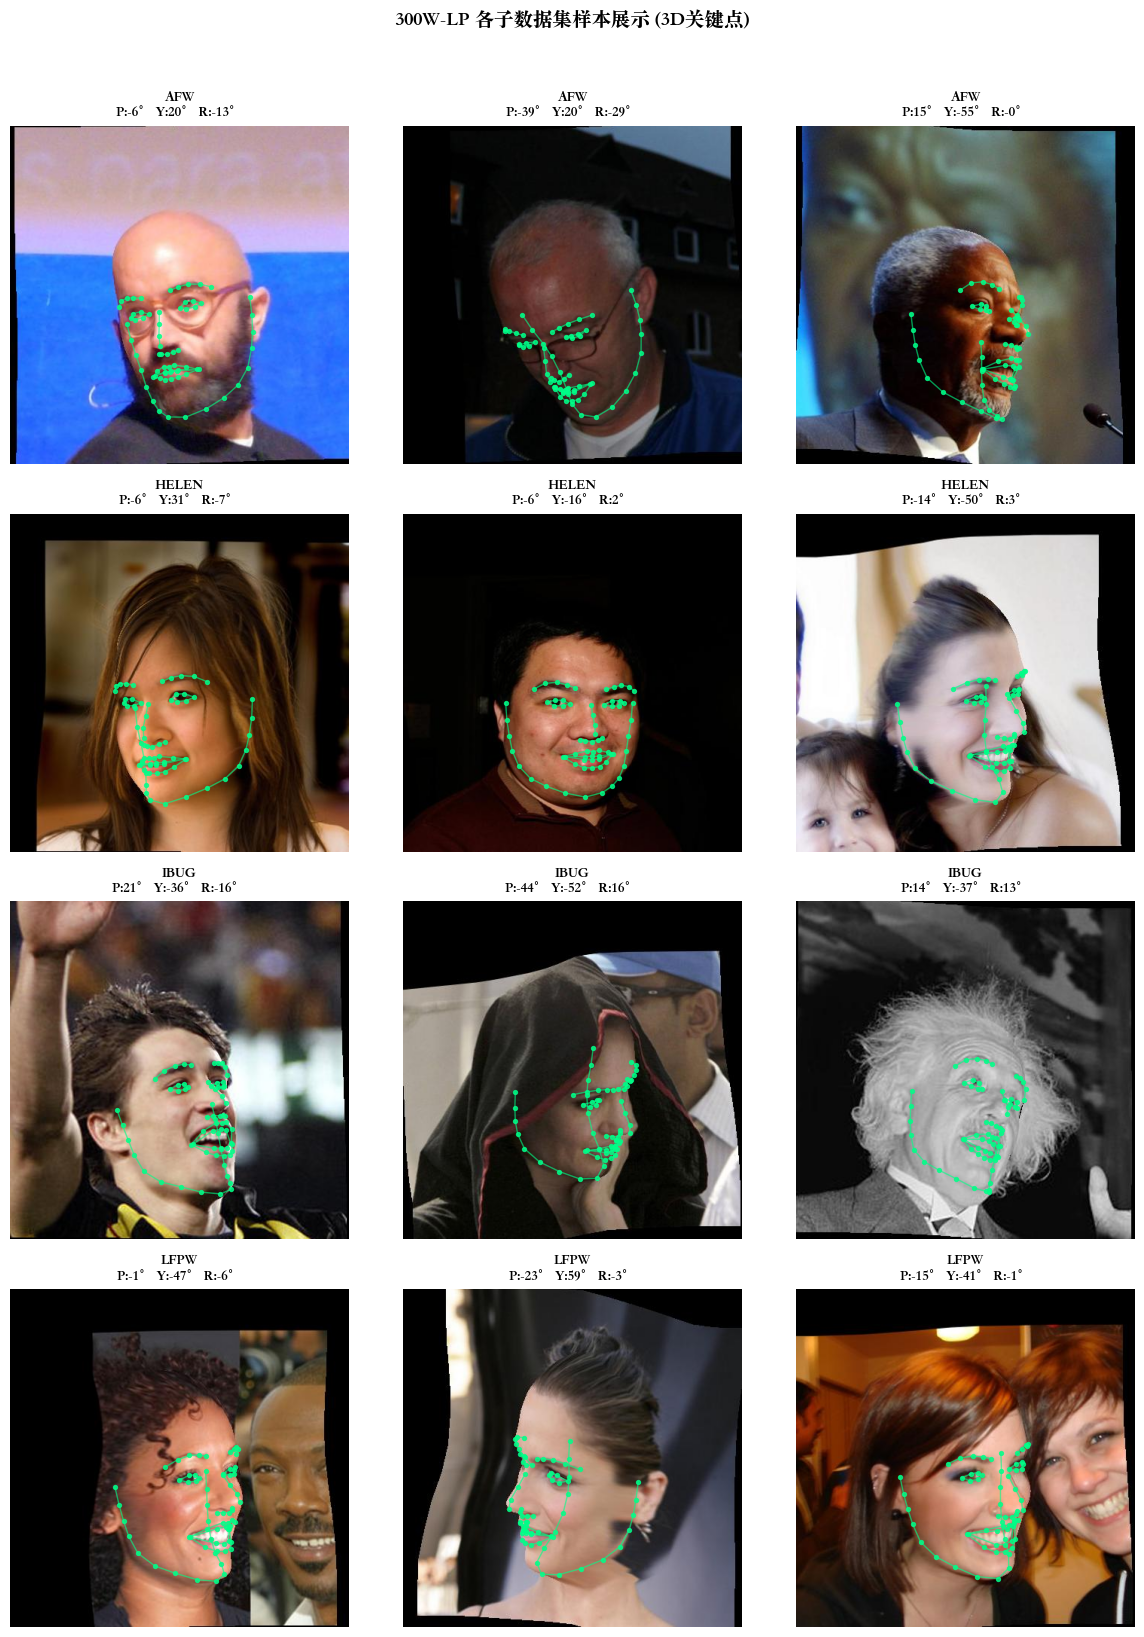

✅ 图表已保存: 300w_lp_sample_faces.png


In [7]:
# 从每个子数据集随机选择样本进行可视化
np.random.seed(42)
n_samples_per_subset = 3

fig, axes = plt.subplots(4, n_samples_per_subset, figsize=(12, 16))

for row_idx, subset in enumerate(SUBSETS):
    subset_path = os.path.join(DATASET_ROOT, subset)
    all_images = glob.glob(os.path.join(subset_path, "*.jpg"))
    
    # 随机选择样本
    selected = np.random.choice(all_images, min(n_samples_per_subset, len(all_images)), replace=False)
    
    for col_idx, img_path in enumerate(selected):
        sample_name = os.path.basename(img_path)
        sample = load_sample(subset, sample_name)
        
        ax = axes[row_idx, col_idx]
        
        if 'image' in sample and 'pts_3d' in sample:
            plot_landmarks_on_image(ax, sample['image'], sample['pts_3d'], color='#00FF88', markersize=8)
            
            # 显示姿态信息
            if 'pose' in sample and len(sample['pose']) >= 3:
                pose = sample['pose']
                pitch, yaw, roll = np.degrees(pose[:3])
                ax.set_title(f"{subset}\nP:{pitch:.0f}° Y:{yaw:.0f}° R:{roll:.0f}°", fontsize=10)
        else:
            ax.set_title(f"{subset}\n(no landmarks)", fontsize=10)
            if 'image' in sample:
                ax.imshow(sample['image'])
            ax.axis('off')

plt.suptitle("300W-LP 各子数据集样本展示 (3D关键点)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('300w_lp_sample_faces.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_sample_faces.png")


## 4. 68点人脸关键点布局

展示标准68点人脸关键点的位置和索引


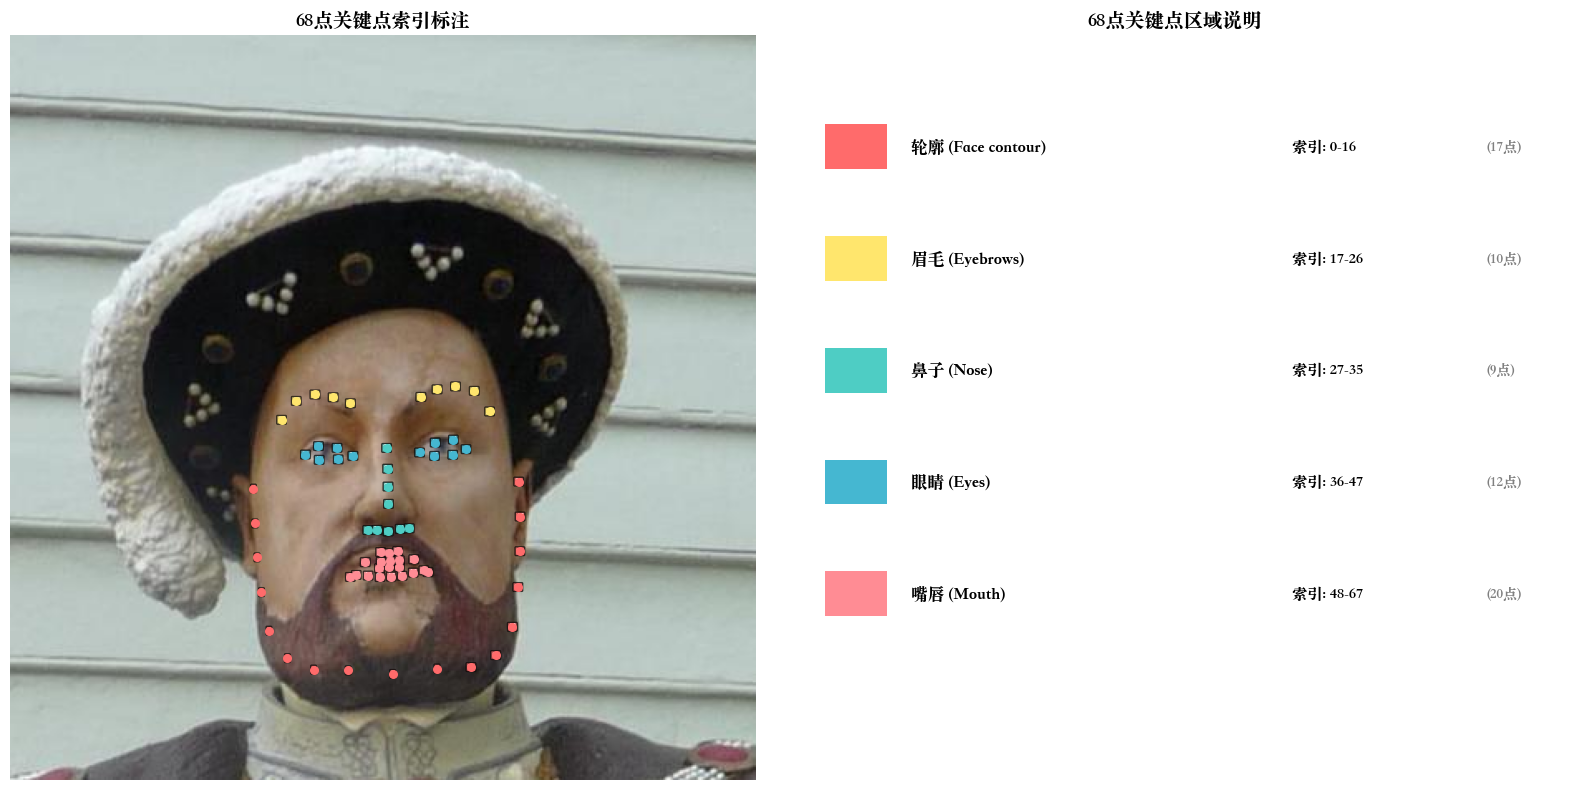

✅ 图表已保存: 300w_lp_68_landmarks_layout.png


In [8]:
# 选择一个正面样本展示68点布局
# 找一个 yaw 接近 0 的样本
subset = "AFW"
subset_path = os.path.join(DATASET_ROOT, subset)
all_mat_files = glob.glob(os.path.join(subset_path, "*.mat"))

best_sample = None
min_yaw = float('inf')

for mat_file in all_mat_files[:500]:  # 只检查前500个
    mat = loadmat(mat_file)
    if 'Pose_Para' in mat:
        yaw = abs(np.degrees(mat['Pose_Para'].flatten()[1]))
        if yaw < min_yaw:
            min_yaw = yaw
            best_sample = os.path.basename(mat_file)

if best_sample:
    sample = load_sample(subset, best_sample)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))
    
    # 左图: 带关键点编号的图像
    ax1 = axes[0]
    if 'image' in sample and 'pts_3d' in sample:
        ax1.imshow(sample['image'])
        pts = sample['pts_3d']
        
        # 使用不同颜色标记不同区域
        regions = {
            '轮廓 (0-16)': (range(0, 17), '#FF6B6B'),
            '左眉 (17-21)': (range(17, 22), '#FFE66D'),
            '右眉 (22-26)': (range(22, 27), '#FFE66D'),
            '鼻子 (27-35)': (range(27, 36), '#4ECDC4'),
            '左眼 (36-41)': (range(36, 42), '#45B7D1'),
            '右眼 (42-47)': (range(42, 48), '#45B7D1'),
            '嘴唇 (48-67)': (range(48, 68), '#FF8C94'),
        }
        
        for region_name, (indices, color) in regions.items():
            for idx in indices:
                ax1.scatter(pts[idx, 0], pts[idx, 1], c=color, s=30, zorder=5)
                ax1.annotate(str(idx), (pts[idx, 0], pts[idx, 1]), 
                           fontsize=6, color='white', ha='center', va='center',
                           bbox=dict(boxstyle='round,pad=0.1', facecolor=color, alpha=0.7))
    
    ax1.set_title("68点关键点索引标注", fontsize=14, fontweight='bold')
    ax1.axis('off')
    
    # 右图: 关键点区域图例
    ax2 = axes[1]
    ax2.set_xlim(0, 10)
    ax2.set_ylim(0, 10)
    
    legend_data = [
        ("轮廓 (Face contour)", "0-16", '#FF6B6B', 17),
        ("眉毛 (Eyebrows)", "17-26", '#FFE66D', 10),
        ("鼻子 (Nose)", "27-35", '#4ECDC4', 9),
        ("眼睛 (Eyes)", "36-47", '#45B7D1', 12),
        ("嘴唇 (Mouth)", "48-67", '#FF8C94', 20),
    ]
    
    y_pos = 8.5
    for name, idx_range, color, count in legend_data:
        ax2.add_patch(plt.Rectangle((0.5, y_pos-0.3), 0.8, 0.6, facecolor=color))
        ax2.text(1.6, y_pos, f"{name}", fontsize=12, va='center', fontweight='bold')
        ax2.text(6.5, y_pos, f"索引: {idx_range}", fontsize=11, va='center')
        ax2.text(9, y_pos, f"({count}点)", fontsize=10, va='center', color='gray')
        y_pos -= 1.5
    
    ax2.set_title("68点关键点区域说明", fontsize=14, fontweight='bold')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.savefig('300w_lp_68_landmarks_layout.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("✅ 图表已保存: 300w_lp_68_landmarks_layout.png")


## 5. 头部姿态分布分析

分析 Pitch, Yaw, Roll 三个欧拉角的分布情况


In [9]:
# 收集所有样本的姿态参数
print("正在收集姿态参数...")

all_poses = []
pose_by_subset = {subset: [] for subset in SUBSETS_WITH_FLIP}

for subset in tqdm(SUBSETS_WITH_FLIP, desc="Processing subsets"):
    subset_path = os.path.join(DATASET_ROOT, subset)
    mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
    
    for mat_file in mat_files:
        try:
            mat = loadmat(mat_file)
            if 'Pose_Para' in mat:
                pose = mat['Pose_Para'].flatten()
                if len(pose) >= 3:
                    # 转换为角度
                    pitch, yaw, roll = np.degrees(pose[:3])
                    all_poses.append([pitch, yaw, roll])
                    pose_by_subset[subset].append([pitch, yaw, roll])
        except Exception as e:
            continue

all_poses = np.array(all_poses)
print(f"\n✅ 共收集 {len(all_poses):,} 个样本的姿态参数")


正在收集姿态参数...


Processing subsets: 100%|██████████| 8/8 [00:18<00:00,  2.36s/it]


✅ 共收集 122,450 个样本的姿态参数


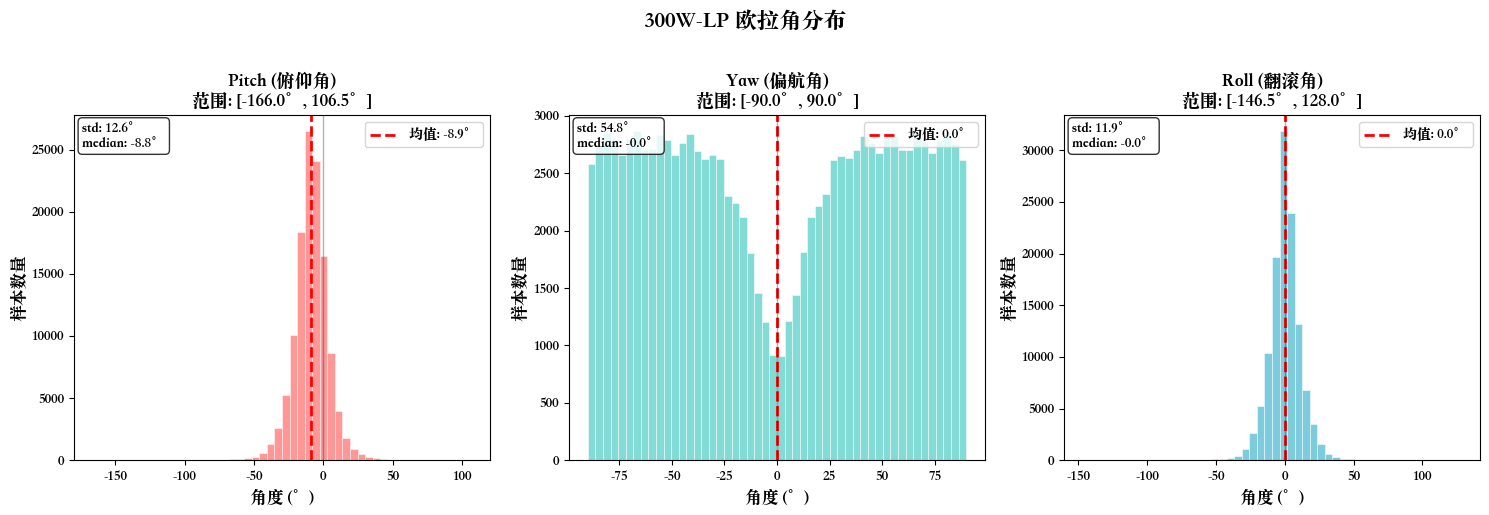

✅ 图表已保存: 300w_lp_euler_angles_distribution.png


In [10]:
# 绘制欧拉角分布直方图
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

angle_names = ['Pitch (俯仰角)', 'Yaw (偏航角)', 'Roll (翻滚角)']
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

for i, (name, color) in enumerate(zip(angle_names, colors)):
    ax = axes[i]
    data = all_poses[:, i]
    
    ax.hist(data, bins=50, color=color, alpha=0.7, edgecolor='white', linewidth=0.5)
    ax.axvline(data.mean(), color='red', linestyle='--', linewidth=2, label=f'均值: {data.mean():.1f}°')
    ax.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.3)
    
    ax.set_xlabel('角度 (°)', fontsize=12)
    ax.set_ylabel('样本数量', fontsize=12)
    ax.set_title(f'{name}\n范围: [{data.min():.1f}°, {data.max():.1f}°]', fontsize=13, fontweight='bold')
    ax.legend(loc='upper right')
    
    # 添加统计信息
    stats_text = f'std: {data.std():.1f}°\nmedian: {np.median(data):.1f}°'
    ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('300W-LP 欧拉角分布', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('300w_lp_euler_angles_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_euler_angles_distribution.png")


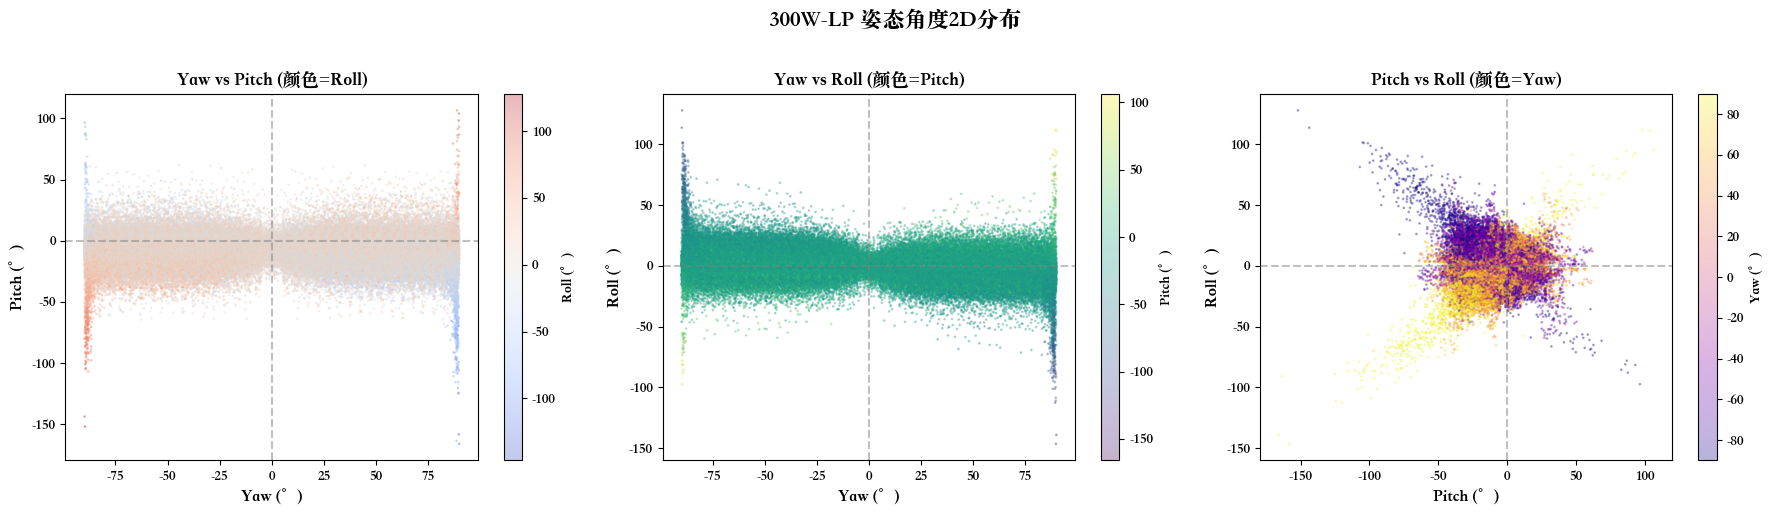

✅ 图表已保存: 300w_lp_pose_2d_distribution.png


In [11]:
# 2D 散点图: Yaw vs Pitch 分布
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Yaw vs Pitch
ax1 = axes[0]
scatter1 = ax1.scatter(all_poses[:, 1], all_poses[:, 0], c=all_poses[:, 2], 
                       cmap='coolwarm', alpha=0.3, s=1)
ax1.set_xlabel('Yaw (°)', fontsize=12)
ax1.set_ylabel('Pitch (°)', fontsize=12)
ax1.set_title('Yaw vs Pitch (颜色=Roll)', fontsize=13, fontweight='bold')
ax1.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax1.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.colorbar(scatter1, ax=ax1, label='Roll (°)')

# Yaw vs Roll
ax2 = axes[1]
scatter2 = ax2.scatter(all_poses[:, 1], all_poses[:, 2], c=all_poses[:, 0], 
                       cmap='viridis', alpha=0.3, s=1)
ax2.set_xlabel('Yaw (°)', fontsize=12)
ax2.set_ylabel('Roll (°)', fontsize=12)
ax2.set_title('Yaw vs Roll (颜色=Pitch)', fontsize=13, fontweight='bold')
ax2.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax2.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.colorbar(scatter2, ax=ax2, label='Pitch (°)')

# Pitch vs Roll
ax3 = axes[2]
scatter3 = ax3.scatter(all_poses[:, 0], all_poses[:, 2], c=all_poses[:, 1], 
                       cmap='plasma', alpha=0.3, s=1)
ax3.set_xlabel('Pitch (°)', fontsize=12)
ax3.set_ylabel('Roll (°)', fontsize=12)
ax3.set_title('Pitch vs Roll (颜色=Yaw)', fontsize=13, fontweight='bold')
ax3.axhline(0, color='gray', linestyle='--', alpha=0.5)
ax3.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.colorbar(scatter3, ax=ax3, label='Yaw (°)')

plt.suptitle('300W-LP 姿态角度2D分布', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('300w_lp_pose_2d_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_pose_2d_distribution.png")


## 6. 不同Yaw角度的样本可视化

展示不同偏航角度下的人脸样本


In [12]:
# 按 Yaw 角度选择样本
yaw_ranges = [(-90, -60), (-60, -30), (-30, 0), (0, 30), (30, 60), (60, 90)]

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for col_idx, (yaw_min, yaw_max) in enumerate(yaw_ranges):
    # 在所有子数据集中寻找符合条件的样本
    found_samples = []
    
    for subset in SUBSETS:
        subset_path = os.path.join(DATASET_ROOT, subset)
        mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
        
        for mat_file in mat_files[:2000]:  # 限制搜索范围
            try:
                mat = loadmat(mat_file)
                if 'Pose_Para' in mat:
                    yaw = np.degrees(mat['Pose_Para'].flatten()[1])
                    if yaw_min <= yaw < yaw_max:
                        found_samples.append((subset, os.path.basename(mat_file), yaw))
                        if len(found_samples) >= 2:
                            break
            except:
                continue
        if len(found_samples) >= 2:
            break
    
    # 显示找到的样本
    for row_idx, (subset, sample_name, yaw) in enumerate(found_samples[:2]):
        sample = load_sample(subset, sample_name)
        ax = axes[row_idx, col_idx]
        
        if 'image' in sample and 'pts_3d' in sample:
            plot_landmarks_on_image(ax, sample['image'], sample['pts_3d'], color='#00FF88', markersize=6)
        elif 'image' in sample:
            ax.imshow(sample['image'])
            ax.axis('off')
        
        if row_idx == 0:
            ax.set_title(f'Yaw: {yaw_min}° ~ {yaw_max}°', fontsize=11, fontweight='bold')

plt.suptitle('不同 Yaw 角度样本展示', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('300w_lp_yaw_samples.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_yaw_samples.png")


✅ 图表已保存: 300w_lp_yaw_samples.png


## 7. RPY 姿态轴可视化

在图像上绘制 Roll, Pitch, Yaw 三个旋转轴，直观展示头部姿态方向：
- **红色 (X轴)**: Roll 旋转轴，指向右侧
- **绿色 (Y轴)**: Pitch 旋转轴，指向下方  
- **蓝色 (Z轴)**: Yaw 旋转轴，指向前方（从脸部射出）


In [17]:
from math import cos, sin

def draw_axis(img, pitch, yaw, roll, tdx, tdy, size=80):
    """
    在图像上绘制头部姿态的 3D 坐标轴
    
    Args:
        img: RGB 图像 (numpy array)
        pitch, yaw, roll: 欧拉角 (弧度)
        tdx, tdy: 坐标轴原点 (通常是鼻尖位置)
        size: 坐标轴长度 (像素)
    
    Returns:
        img_draw: 绘制了坐标轴的图像
    
    坐标轴颜色:
        - 红色 (X): Roll 轴，指向右侧
        - 绿色 (Y): Pitch 轴，指向下方
        - 蓝色 (Z): Yaw 轴，指向前方 (从脸部射出)
    """
    img_draw = img.copy()
    yaw = -yaw  # 符号约定调整
    
    # X-Axis (红色) - Roll
    x1 = size * (cos(yaw) * cos(roll)) + tdx
    y1 = size * (cos(pitch) * sin(roll) + cos(roll) * sin(pitch) * sin(yaw)) + tdy
    
    # Y-Axis (绿色) - Pitch
    x2 = size * (-cos(yaw) * sin(roll)) + tdx
    y2 = size * (cos(pitch) * cos(roll) - sin(pitch) * sin(yaw) * sin(roll)) + tdy
    
    # Z-Axis (蓝色) - Yaw
    x3 = size * (sin(yaw)) + tdx
    y3 = size * (-cos(yaw) * sin(pitch)) + tdy
    
    # 使用 cv2 绘制 (需要 BGR，但我们的图像是 RGB，颜色顺序需要对调)
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x1), int(y1)), (255, 0, 0), 3)   # 红色 X
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x2), int(y2)), (0, 255, 0), 3)   # 绿色 Y
    cv2.line(img_draw, (int(tdx), int(tdy)), (int(x3), int(y3)), (0, 0, 255), 3)   # 蓝色 Z
    
    return img_draw

def get_nose_tip(pts):
    """从68个关键点中获取鼻尖位置 (索引30)"""
    if pts is not None and len(pts) > 30:
        return pts[30, 0], pts[30, 1]
    return None, None

print("✅ RPY 姿态轴绘制函数定义完成")


✅ RPY 姿态轴绘制函数定义完成


In [ ]:
# 展示不同姿态下的 RPY 轴可视化
# 选择多个代表性样本，展示不同 yaw 角度下的姿态轴
# 先通过 ROI 裁剪面部区域，再在裁剪后的面部上绘制姿态轴

yaw_ranges = [(-90, -60), (-60, -30), (-30, 0), (0, 30), (30, 60), (60, 90)]
fig, axes = plt.subplots(2, 6, figsize=(20, 8))

for col_idx, (yaw_min, yaw_max) in enumerate(yaw_ranges):
    found_samples = []
    
    for subset in SUBSETS:
        subset_path = os.path.join(DATASET_ROOT, subset)
        mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
        
        for mat_file in mat_files[:3000]:
            try:
                mat = loadmat(mat_file)
                if 'Pose_Para' in mat:
                    pose = mat['Pose_Para'].flatten()
                    yaw = np.degrees(pose[1])
                    if yaw_min <= yaw < yaw_max:
                        found_samples.append((subset, os.path.basename(mat_file), pose))
                        if len(found_samples) >= 2:
                            break
            except:
                continue
        if len(found_samples) >= 2:
            break
    
    for row_idx, (subset, sample_name, pose) in enumerate(found_samples[:2]):
        sample = load_sample(subset, sample_name)
        ax = axes[row_idx, col_idx]
        
        if 'image' in sample:
            img = sample['image'].copy()
            
            # 使用 ROI 裁剪面部区域
            roi = sample.get('roi', None)
            x1_off, y1_off = 0, 0
            if roi is not None and len(roi) == 4:
                rx1, ry1, rx2, ry2 = int(roi[0]), int(roi[1]), int(roi[2]), int(roi[3])
                h, w = img.shape[:2]
                rx1, ry1 = max(0, rx1), max(0, ry1)
                rx2, ry2 = min(w, rx2), min(h, ry2)
                face_crop = img[ry1:ry2, rx1:rx2]
                x1_off, y1_off = rx1, ry1
            else:
                face_crop = img
            
            # 获取鼻尖位置并转换为裁剪区域内的坐标
            nose_x, nose_y = None, None
            if 'pts_3d' in sample and sample['pts_3d'] is not None:
                nose_x, nose_y = get_nose_tip(sample['pts_3d'])
                if nose_x is not None:
                    nose_x -= x1_off
                    nose_y -= y1_off
            
            if nose_x is None:
                nose_x = face_crop.shape[1] // 2
                nose_y = face_crop.shape[0] // 2
            
            # 根据裁剪区域大小自适应轴长度
            axis_size = min(face_crop.shape[0], face_crop.shape[1]) // 3
            
            pitch_rad, yaw_rad, roll_rad = pose[:3]
            img_with_axis = draw_axis(face_crop, pitch_rad, yaw_rad, roll_rad, nose_x, nose_y, size=axis_size)
            
            ax.imshow(img_with_axis)
            
            pitch_deg, yaw_deg, roll_deg = np.degrees(pose[:3])
            if row_idx == 0:
                ax.set_title(f'Yaw: {yaw_min}\u00b0 ~ {yaw_max}\u00b0', fontsize=11, fontweight='bold')
            
            ax.text(0.5, -0.02, f'P:{pitch_deg:.0f}\u00b0 Y:{yaw_deg:.0f}\u00b0 R:{roll_deg:.0f}\u00b0', 
                   transform=ax.transAxes, fontsize=9, ha='center', va='top')
        
        ax.axis('off')

legend_text = "坐标轴: 红色=X(Roll) | 绿色=Y(Pitch) | 蓝色=Z(Yaw)"
fig.text(0.5, 0.02, legend_text, ha='center', fontsize=12, style='italic',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle('300W-LP RPY 姿态轴可视化 - 面部裁剪 (不同 Yaw 角度)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig('300w_lp_pose_axes_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("\u2705 图表已保存: 300w_lp_pose_axes_visualization.png")


In [ ]:
# 展示不同 Pitch 角度下的 RPY 轴可视化
# 先通过 ROI 裁剪面部区域，再在裁剪后的面部上绘制姿态轴
pitch_ranges = [(-60, -40), (-40, -20), (-20, 0), (0, 20), (20, 40), (40, 60)]
fig, axes = plt.subplots(2, 6, figsize=(20, 8))

for col_idx, (pitch_min, pitch_max) in enumerate(pitch_ranges):
    found_samples = []
    
    for subset in SUBSETS:
        subset_path = os.path.join(DATASET_ROOT, subset)
        mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
        
        for mat_file in mat_files[:5000]:
            try:
                mat = loadmat(mat_file)
                if 'Pose_Para' in mat:
                    pose = mat['Pose_Para'].flatten()
                    pitch = np.degrees(pose[0])
                    yaw = np.degrees(pose[1])
                    if pitch_min <= pitch < pitch_max and abs(yaw) < 30:
                        found_samples.append((subset, os.path.basename(mat_file), pose))
                        if len(found_samples) >= 2:
                            break
            except:
                continue
        if len(found_samples) >= 2:
            break
    
    for row_idx in range(2):
        ax = axes[row_idx, col_idx]
        
        if row_idx < len(found_samples):
            subset, sample_name, pose = found_samples[row_idx]
            sample = load_sample(subset, sample_name)
            
            if 'image' in sample:
                img = sample['image'].copy()
                
                # 使用 ROI 裁剪面部区域
                roi = sample.get('roi', None)
                x1_off, y1_off = 0, 0
                if roi is not None and len(roi) == 4:
                    rx1, ry1, rx2, ry2 = int(roi[0]), int(roi[1]), int(roi[2]), int(roi[3])
                    h, w = img.shape[:2]
                    rx1, ry1 = max(0, rx1), max(0, ry1)
                    rx2, ry2 = min(w, rx2), min(h, ry2)
                    face_crop = img[ry1:ry2, rx1:rx2]
                    x1_off, y1_off = rx1, ry1
                else:
                    face_crop = img
                
                # 获取鼻尖位置并转换为裁剪区域内的坐标
                nose_x, nose_y = None, None
                if 'pts_3d' in sample and sample['pts_3d'] is not None:
                    nose_x, nose_y = get_nose_tip(sample['pts_3d'])
                    if nose_x is not None:
                        nose_x -= x1_off
                        nose_y -= y1_off
                
                if nose_x is None:
                    nose_x = face_crop.shape[1] // 2
                    nose_y = face_crop.shape[0] // 2
                
                # 根据裁剪区域大小自适应轴长度
                axis_size = min(face_crop.shape[0], face_crop.shape[1]) // 3
                
                pitch_rad, yaw_rad, roll_rad = pose[:3]
                img_with_axis = draw_axis(face_crop, pitch_rad, yaw_rad, roll_rad, nose_x, nose_y, size=axis_size)
                
                ax.imshow(img_with_axis)
                
                pitch_deg, yaw_deg, roll_deg = np.degrees(pose[:3])
                if row_idx == 0:
                    ax.set_title(f'Pitch: {pitch_min}\u00b0 ~ {pitch_max}\u00b0', fontsize=11, fontweight='bold')
                
                ax.text(0.5, -0.02, f'P:{pitch_deg:.0f}\u00b0 Y:{yaw_deg:.0f}\u00b0 R:{roll_deg:.0f}\u00b0', 
                       transform=ax.transAxes, fontsize=9, ha='center', va='top')
        
        ax.axis('off')

legend_text = "坐标轴: 红色=X(Roll) | 绿色=Y(Pitch) | 蓝色=Z(Yaw)"
fig.text(0.5, 0.02, legend_text, ha='center', fontsize=12, style='italic',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.suptitle('300W-LP RPY 姿态轴可视化 - 面部裁剪 (不同 Pitch 角度)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig('300w_lp_pitch_samples.png', dpi=150, bbox_inches='tight')
plt.show()

print("\u2705 图表已保存: 300w_lp_pitch_samples.png")


## 8. 图像尺寸分析

分析数据集中图像的分辨率分布


In [13]:
# 分析图像尺寸 (采样一部分图像)
print("正在分析图像尺寸...")

image_sizes = []
image_sizes_by_subset = {subset: [] for subset in SUBSETS}

np.random.seed(42)

for subset in tqdm(SUBSETS, desc="Processing subsets"):
    subset_path = os.path.join(DATASET_ROOT, subset)
    all_images = glob.glob(os.path.join(subset_path, "*.jpg"))
    
    # 每个子集采样最多 500 张
    sampled = np.random.choice(all_images, min(500, len(all_images)), replace=False)
    
    for img_path in sampled:
        try:
            img = cv2.imread(img_path)
            if img is not None:
                h, w = img.shape[:2]
                image_sizes.append([w, h])
                image_sizes_by_subset[subset].append([w, h])
        except:
            continue

image_sizes = np.array(image_sizes)
print(f"\n✅ 分析了 {len(image_sizes):,} 张图像")


正在分析图像尺寸...


Processing subsets: 100%|██████████| 4/4 [00:01<00:00,  3.67it/s]


✅ 分析了 2,000 张图像


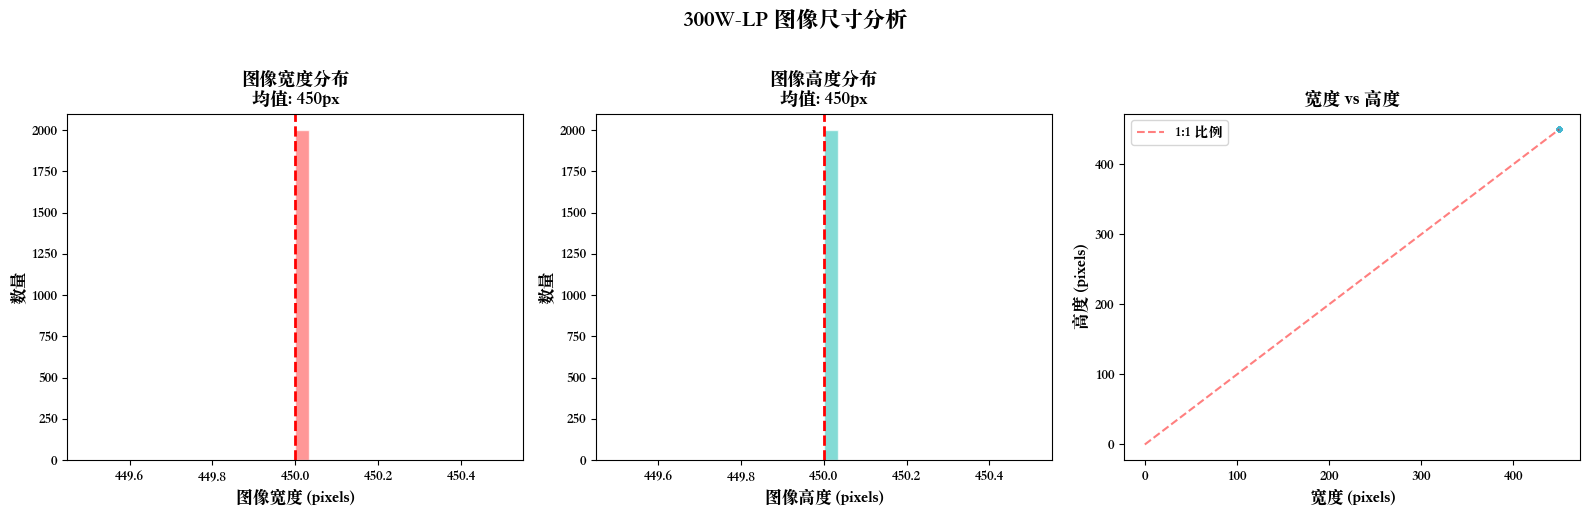


📊 图像尺寸统计:
   宽度范围: [450, 450] px
   高度范围: [450, 450] px
   平均尺寸: 450 x 450 px

✅ 图表已保存: 300w_lp_image_size_distribution.png


In [14]:
# 可视化图像尺寸分布
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 宽度分布
ax1 = axes[0]
ax1.hist(image_sizes[:, 0], bins=30, color='#FF6B6B', alpha=0.7, edgecolor='white')
ax1.set_xlabel('图像宽度 (pixels)', fontsize=12)
ax1.set_ylabel('数量', fontsize=12)
ax1.set_title(f'图像宽度分布\n均值: {image_sizes[:, 0].mean():.0f}px', fontsize=13, fontweight='bold')
ax1.axvline(image_sizes[:, 0].mean(), color='red', linestyle='--', linewidth=2)

# 高度分布
ax2 = axes[1]
ax2.hist(image_sizes[:, 1], bins=30, color='#4ECDC4', alpha=0.7, edgecolor='white')
ax2.set_xlabel('图像高度 (pixels)', fontsize=12)
ax2.set_ylabel('数量', fontsize=12)
ax2.set_title(f'图像高度分布\n均值: {image_sizes[:, 1].mean():.0f}px', fontsize=13, fontweight='bold')
ax2.axvline(image_sizes[:, 1].mean(), color='red', linestyle='--', linewidth=2)

# 宽高散点图
ax3 = axes[2]
ax3.scatter(image_sizes[:, 0], image_sizes[:, 1], alpha=0.3, s=10, c='#45B7D1')
ax3.set_xlabel('宽度 (pixels)', fontsize=12)
ax3.set_ylabel('高度 (pixels)', fontsize=12)
ax3.set_title('宽度 vs 高度', fontsize=13, fontweight='bold')
# 添加 1:1 线
max_dim = max(image_sizes.max(), image_sizes.max())
ax3.plot([0, max_dim], [0, max_dim], 'r--', alpha=0.5, label='1:1 比例')
ax3.legend()

plt.suptitle('300W-LP 图像尺寸分析', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('300w_lp_image_size_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

# 输出统计信息
print("\n📊 图像尺寸统计:")
print(f"   宽度范围: [{image_sizes[:, 0].min():.0f}, {image_sizes[:, 0].max():.0f}] px")
print(f"   高度范围: [{image_sizes[:, 1].min():.0f}, {image_sizes[:, 1].max():.0f}] px")
print(f"   平均尺寸: {image_sizes[:, 0].mean():.0f} x {image_sizes[:, 1].mean():.0f} px")

print("\n✅ 图表已保存: 300w_lp_image_size_distribution.png")


## 9. 各子数据集姿态分布对比

分析不同子数据集的姿态角度分布差异


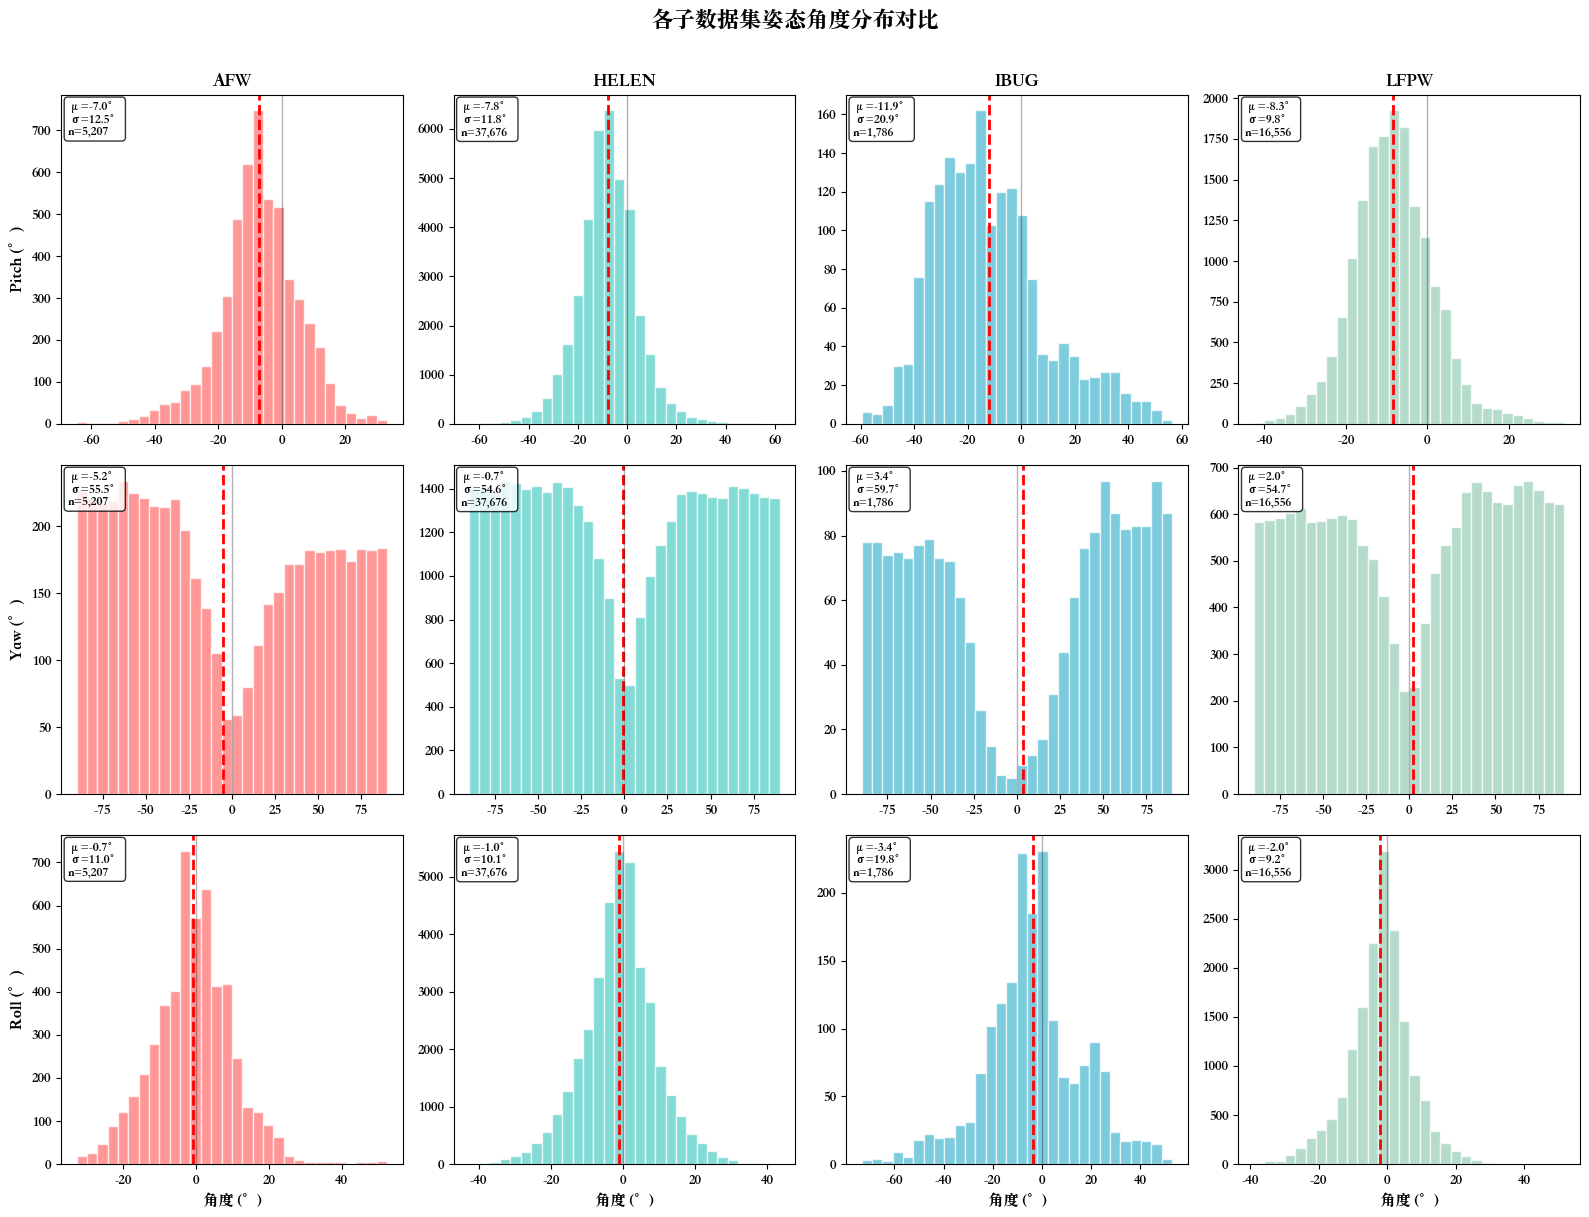

✅ 图表已保存: 300w_lp_pose_by_subset.png


In [15]:
# 各子数据集的姿态分布对比 (仅原始版本)
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

angle_names = ['Pitch', 'Yaw', 'Roll']
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4']

for row_idx, angle_name in enumerate(angle_names):
    for col_idx, subset in enumerate(SUBSETS):
        ax = axes[row_idx, col_idx]
        
        if subset in pose_by_subset and len(pose_by_subset[subset]) > 0:
            poses = np.array(pose_by_subset[subset])
            data = poses[:, row_idx]
            
            ax.hist(data, bins=30, color=colors[col_idx], alpha=0.7, edgecolor='white')
            ax.axvline(data.mean(), color='red', linestyle='--', linewidth=2)
            ax.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.3)
            
            stats_text = f'μ={data.mean():.1f}°\nσ={data.std():.1f}°\nn={len(data):,}'
            ax.text(0.02, 0.98, stats_text, transform=ax.transAxes, fontsize=9,
                    verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        if row_idx == 0:
            ax.set_title(subset, fontsize=13, fontweight='bold')
        if col_idx == 0:
            ax.set_ylabel(f'{angle_name} (°)', fontsize=12)
        if row_idx == 2:
            ax.set_xlabel('角度 (°)', fontsize=11)

plt.suptitle('各子数据集姿态角度分布对比', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('300w_lp_pose_by_subset.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ 图表已保存: 300w_lp_pose_by_subset.png")


## 10. 数据加载工具函数

提供用于训练的数据加载工具函数


In [16]:
class W300LPDataset:
    """300W-LP 数据集加载器
    
    用于加载图像、姿态参数和关键点标注
    """
    
    def __init__(self, root_dir, subsets=None, include_flip=False):
        """
        Args:
            root_dir: 数据集根目录
            subsets: 要加载的子数据集列表，默认为全部 ['AFW', 'HELEN', 'IBUG', 'LFPW']
            include_flip: 是否包含翻转版本
        """
        self.root_dir = root_dir
        self.subsets = subsets or ['AFW', 'HELEN', 'IBUG', 'LFPW']
        
        if include_flip:
            self.subsets = self.subsets + [f"{s}_Flip" for s in self.subsets]
        
        self.samples = self._load_samples()
    
    def _load_samples(self):
        """扫描所有样本"""
        samples = []
        
        for subset in self.subsets:
            subset_path = os.path.join(self.root_dir, subset)
            if not os.path.exists(subset_path):
                continue
            
            mat_files = glob.glob(os.path.join(subset_path, "*.mat"))
            
            for mat_file in mat_files:
                base_name = os.path.basename(mat_file).replace('.mat', '')
                img_path = os.path.join(subset_path, f"{base_name}.jpg")
                
                if os.path.exists(img_path):
                    samples.append({
                        'subset': subset,
                        'name': base_name,
                        'image_path': img_path,
                        'mat_path': mat_file
                    })
        
        return samples
    
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        """获取单个样本
        
        Returns:
            dict: 包含 image, pose (pitch, yaw, roll in degrees), 
                  pts_2d, pts_3d (如果存在)
        """
        sample_info = self.samples[idx]
        
        # 加载图像
        image = cv2.cvtColor(cv2.imread(sample_info['image_path']), cv2.COLOR_BGR2RGB)
        
        # 加载参数
        mat = loadmat(sample_info['mat_path'])
        pose_rad = mat['Pose_Para'].flatten()[:3]
        pose_deg = np.degrees(pose_rad)  # pitch, yaw, roll
        
        result = {
            'image': image,
            'pose': pose_deg,  # [pitch, yaw, roll] in degrees
            'name': sample_info['name'],
            'subset': sample_info['subset']
        }
        
        # 尝试加载关键点
        subset_base = sample_info['subset'].replace('_Flip', '')
        landmark_path = os.path.join(
            self.root_dir, "landmarks", subset_base, 
            f"{sample_info['name']}_pts.mat"
        )
        
        if os.path.exists(landmark_path):
            landmark_mat = loadmat(landmark_path)
            result['pts_2d'] = landmark_mat.get('pts_2d', None)
            result['pts_3d'] = landmark_mat.get('pts_3d', None)
        
        return result

# 使用示例
print("=" * 60)
print("300W-LP 数据集加载器示例")
print("=" * 60)

dataset = W300LPDataset(DATASET_ROOT, subsets=['AFW'], include_flip=False)
print(f"\n✅ 加载了 {len(dataset)} 个样本")

# 加载一个样本
sample = dataset[0]
print(f"\n📦 样本结构:")
print(f"   - image shape: {sample['image'].shape}")
print(f"   - pose (P, Y, R): [{sample['pose'][0]:.1f}°, {sample['pose'][1]:.1f}°, {sample['pose'][2]:.1f}°]")
if 'pts_3d' in sample and sample['pts_3d'] is not None:
    print(f"   - pts_3d shape: {sample['pts_3d'].shape}")


300W-LP 数据集加载器示例

✅ 加载了 5207 个样本

📦 样本结构:
   - image shape: (450, 450, 3)
   - pose (P, Y, R): [-1.9°, 52.6°, 7.5°]
   - pts_3d shape: (68, 2)


## 11. 总结

### 数据集特点

1. **大姿态覆盖**: 300W-LP 的主要特点是 Yaw 角度范围扩展至 [-90°, +90°]，适合训练大姿态头部姿态估计模型

2. **丰富的标注**: 
   - 68个2D/3D人脸关键点
   - 完整的姿态参数 (pitch, yaw, roll, translation, scale)
   - 3D形变模型参数 (形状、表情、颜色、光照)

3. **数据增强**: 提供翻转版本(Flip)，有效增加训练数据量

4. **多来源数据**: 整合 AFW, HELEN, IBUG, LFPW 四个数据集，提供多样化的人脸样本

### 使用建议

- **头部姿态估计**: 使用 `Pose_Para` 中的前三个参数 (pitch, yaw, roll)
- **人脸关键点检测**: 使用 `landmarks/` 目录下的 `pts_3d` (推荐) 或 `pts_2d`
- **数据增强**: 可使用 Flip 版本增加训练样本
- **注意**: MAT文件中的角度为**弧度制**，使用时需转换为角度制

### 参考文献

- Zhu, X., Lei, Z., Liu, X., Shi, H., & Li, S. Z. (2016). Face alignment across large poses: A 3d solution. In Proceedings of the IEEE conference on computer vision and pattern recognition (pp. 146-155).
